# 18 — Kombinasi Bobot-Sama dan Uji Stres terhadap Drift Adaptif

**Latar belakang.** Rata-rata sederhana (bobot sama) dari prediksi banyak model adalah cara paling murah untuk menurunkan derau prediksi **tanpa memilih model dari hasil uji**; dalam literatur kombinasi peramalan, bobot sama sulit dikalahkan (Bates & Granger, 1969; Timmermann, 2006). Notebook ini menjawab dua pertanyaan: (a) apakah kombinasi bobot-sama mengalahkan Drift, dan (b) **dari mana** keunggulannya berasal.

Pertanyaan (b) penting karena periode uji adalah reli panjang: rata-rata return h-hari pada uji jauh di atas rata-rata train, sehingga Drift resmi (rata-rata train) *tertinggal secara sistematis*. Model yang sekadar menaikkan rata-rata prediksinya mengikuti reli akan tampak "lebih baik dari Drift" tanpa punya kemampuan meramal pergerakan. Untuk memisahkan keduanya dipakai tiga pembanding (sama dengan notebook 17) dan satu diagnosis:

- **Drift resmi** (rata-rata train), **Drift ekspansif** dan **Drift bergulir 250 hari** (kausal, nol parameter terlatih). Rata-rata historis ekspansif adalah pembanding standar dalam literatur prediksi return aset (Welch & Goyal, 2008; Campbell & Thompson, 2008).
- **Konstanta-oracle**: konstanta = rata-rata return **uji**. Tidak layak dipakai (memakai data uji); hanya untuk menunjukkan *batas atas* penghematan MSE yang bisa dicapai oleh konstanta saja (pergeseran level). Kombinasi yang mengalahkan konstanta-oracle berarti membawa informasi yang berubah menurut waktu; kombinasi yang kalah darinya paling jauh hanya mengejar pergeseran level.

**Protokol (tetap sebelum dijalankan; semua hasil dilaporkan).**

- Tiga resep tetap: `EW_semua21` (21 model), `EW_ML10` (10 ML), `EW_DL11` (11 DL, termasuk DPformer). Kombinasi = rata-rata sederhana prediksi **return h-hari** pada tiap origin uji. Tidak ada bobot yang dilatih dan tidak ada pemilihan model.
- 3 resep × 5 horizon × 2 setup = **30 uji**; koreksi BH atas ke-30 uji itu (per pembanding).
- Statistik sama dengan notebook 10 (DM–HLN, loss kuadrat ruang return).
- **Status analisis: sekunder/eksploratif.** Resep ditetapkan sebelum dihitung, tetapi pratinjau pada periode uji yang sama sudah dilihat; pembanding adaptif dan konstanta-oracle ditambahkan post hoc. Bukan uji konfirmatori.

**Catatan penting.** MSE kombinasi **selalu** ≤ rata-rata MSE anggotanya (konveksitas kuadrat), jadi "kombinasi lebih baik daripada anggota tipikal" bukan temuan empiris. Kolom `mse_mean_member_vs_drift` menunjukkan besar efek rata-rata itu.

In [1]:
import sys, os, json, time, warnings

# Batasi thread CPU supaya laptop tetap responsif. Default 2 thread; ubah lewat env TA_THREADS.
# Harus di kernel BARU (sebelum numpy aktif).
N_THREADS = int(os.environ.get('TA_THREADS', '2'))
for _v in ('OMP_NUM_THREADS', 'MKL_NUM_THREADS', 'OPENBLAS_NUM_THREADS'):
    os.environ.setdefault(_v, str(N_THREADS))

sys.path.insert(0, os.path.join('..'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src.config import OUT, HORIZONS, SETUPS, ML_MODELS, DL_MODELS, ALL_MODELS, LANG, PROTOCOL, ML_REV, QUICK
from src import analysis as A, plots as P, stats as S, ekstra as X
from src.runners import load_data, data_fingerprint

P.set_lang(LANG)
RES = os.path.join(OUT, 'results')
FIGS = os.path.join(OUT, 'figures')
for _d in (RES, FIGS):
    os.makedirs(_d, exist_ok=True)

df, p, exo = load_data('..')
DATA_HASH = data_fingerprint(df)
print(f'Data: {len(p)} hari kerja, {p.index[0].date()} s.d. {p.index[-1].date()} | sidik jari {DATA_HASH}'
      + (' | MODE QUICK (hasil hanya uji kelancaran)' if QUICK else ''))
if not os.path.isdir(os.path.join(RES, 'runs')):
    raise FileNotFoundError('results/runs/ belum ada: jalankan notebook 05-07 (atau salin hasil referensi) terlebih dahulu.')


def simpan(fig, nama):
    P.save_fig(fig, nama, FIGS)
    plt.show()
    plt.close(fig)


Data: 4325 hari kerja, 2010-01-05 s.d. 2026-08-03 | sidik jari 7aea8db80d44


## 1. Tabel kombinasi (30 uji)

In [2]:
# pagar kausalitas Drift adaptif: dihitung ulang hanya dari harga sampai origin; kontrol positif (versi bocor) harus berbeda
CAUS = X.check_bench_causal(p, HORIZONS)
print('[OK] Drift ekspansif dan bergulir kausal (selisih ~ 0), kontrol positif peka (selisih versi bocor > 0):')
display(CAUS.set_index('horizon'))

C = X.combo_table(RES, p, SETUPS, HORIZONS)
n_harap = len(X.RECIPES) * len(HORIZONS) * len(SETUPS)
assert len(C) == n_harap, f'{len(C)} kombinasi, seharusnya {n_harap}: ada run yang belum ada (jalankan notebook 05-07).'
if (C.k != C.k_nominal).any():
    print('[PERHATIAN] sebagian resep memakai anggota lebih sedikit dari nominal:')
    display(C[C.k != C.k_nominal][['setup', 'horizon', 'resep', 'k', 'k_nominal']])
C['hemat_vs_drift_pct'] = 100 * (1 - C.rel_drift)
C['batas_konstanta_pct'] = 100 * (1 - C.rel_oracle_vs_drift)
C.to_csv(os.path.join(RES, 'kombinasi_vs_pembanding.csv'), index=False)

LS = X.level_shift_table(p, HORIZONS)
LS.to_csv(os.path.join(RES, 'pergeseran_level_pembanding.csv'), index=False)
print('Pergeseran level (rel_* = MSE pembanding / MSE Drift resmi; < 1 = lebih baik dari Drift resmi):')
display(LS.round(4).set_index('horizon'))

rows = []
for b in X.BENCH:
    rows.append({'pembanding': X.bench_label(b), 'rasio<1': int((C[f'rel_{b}'] < 1).sum()), 'p<0,05': int((C[f'p_{b}'] < 0.05).sum()),
                 'lolos BH (30 uji)': int((C[f'q_{b}'] < 0.05).sum()), 'dari': len(C)})
rows.append({'pembanding': 'konstanta-oracle (tidak layak)', 'rasio<1': int((C.rel_combo_vs_oracle < 1).sum()),
             'p<0,05': np.nan, 'lolos BH (30 uji)': np.nan, 'dari': len(C)})
print('\nKombinasi vs pembanding (jumlah dari 30; untuk konstanta-oracle: jumlah kombinasi yang MSE-nya LEBIH KECIL dari konstanta itu):')
display(pd.DataFrame(rows).set_index('pembanding'))

[OK] Drift ekspansif dan bergulir kausal (selisih ~ 0), kontrol positif peka (selisih versi bocor > 0):


,n_origin_dicek,selisih_maks,selisih_kontrol_bocor
horizon,,,
1,25,1.019150e-17,0.000006
5,25,4.423545e-17,0.000011
10,25,1.045171e-16,0.000024
20,25,1.179612e-16,0.000034
30,25,2.151057e-16,0.000041


Pergeseran level (rel_* = MSE pembanding / MSE Drift resmi; < 1 = lebih baik dari Drift resmi):


,n,mu_train_pct,mean_uji_pct,rel_drift_exp,rel_drift_roll,rel_oracle_konstan,maks_hemat_konstan_pct
horizon,,,,,,,
1,864,0.0295,0.1081,0.9989,0.9964,0.9935,0.6534
5,864,0.1446,0.5374,0.9941,0.9762,0.9668,3.3166
10,863,0.2919,1.0847,0.9893,0.9569,0.9375,6.2486
20,861,0.5959,2.1798,0.9815,0.9165,0.8844,11.5650
30,859,0.9078,3.3477,0.9772,0.8958,0.8407,15.9259



Kombinasi vs pembanding (jumlah dari 30; untuk konstanta-oracle: jumlah kombinasi yang MSE-nya LEBIH KECIL dari konstanta itu):


,rasio<1,"p<0,05",lolos BH (30 uji),dari
pembanding,,,,
Drift (rata-rata train),26,8.0,0.0,30
Drift ekspansif (kausal),20,2.0,0.0,30
Drift bergulir 250 hari (kausal),2,0.0,0.0,30
konstanta-oracle (tidak layak),0,NaN,NaN,30


## 2. Figur

- **Garis (kiri/kanan = univariat/multivariat):** MSE-return relatif terhadap Drift resmi (garis hitam = 1). Garis abu-abu = Drift adaptif kausal; garis titik-titik = konstanta-oracle (batas bawah untuk konstanta). Kombinasi yang berada di antara 1 dan garis Drift bergulir hanya "mengejar rata-rata".
- **Peta panas:** rasio kombinasi/pembanding untuk tiga pembanding berdampingan. Biru = kombinasi lebih baik. `*` p < 0,05; `†` lolos BH atas 30 uji.

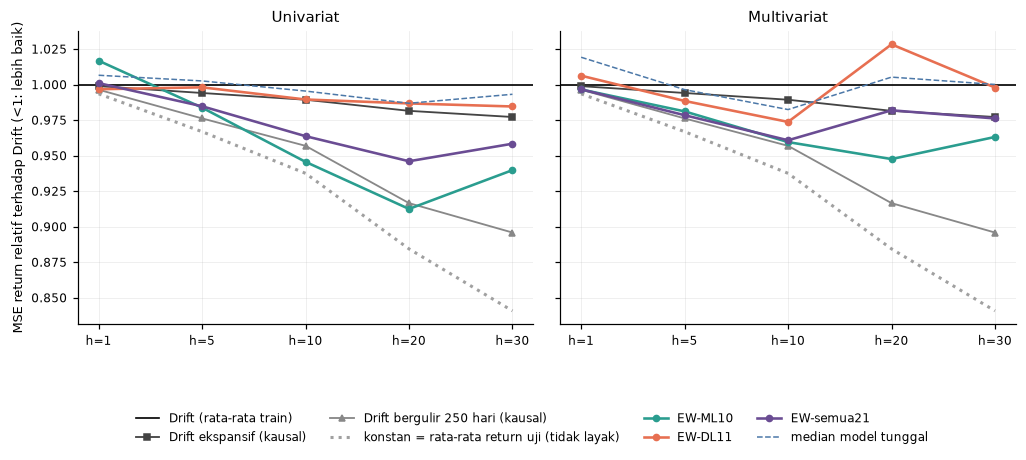

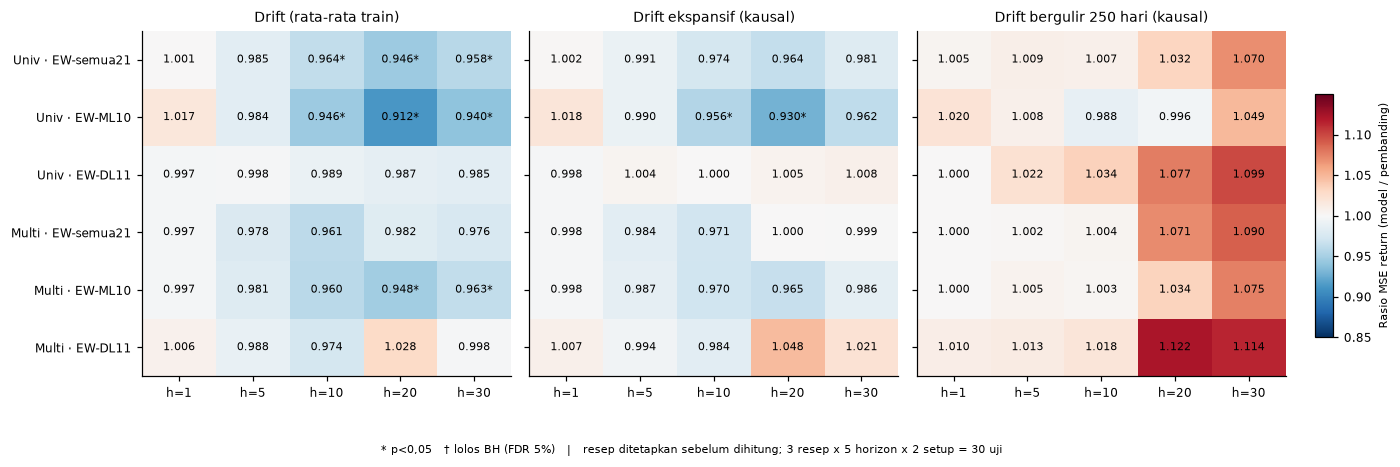

In [3]:
single_med = X.single_ci_table(RES, p, SETUPS, ALL_MODELS, HORIZONS, benches=('drift',))
single_med = single_med.groupby(['setup', 'horizon']).rel_mse.median().reset_index()
fig = X.fig_combo_ladder(C, LS, single_med, HORIZONS)
simpan(fig, 'fig_kombinasi_tangga_pembanding')
fig = X.fig_combo_heat(C, HORIZONS)
simpan(fig, 'fig_kombinasi_vs_pembanding')

## 3. Diagnosis per kombinasi

In [4]:
cols = ['hemat_vs_drift_pct', 'batas_konstanta_pct', 'rel_drift', 'rel_drift_exp', 'rel_drift_roll', 'rel_combo_vs_oracle',
        'mse_mean_member_vs_drift', 'std_ratio', 'pred_up', 'mean_pred_pct', 'mean_true_pct']
display(C.set_index(['setup', 'horizon', 'resep'])[cols].round(3))

hemat_vs_drift_pct  batas_konstanta_pct  \
setup       horizon resep                                                 
univariat   1       EW_semua21              -0.099                0.653   
                    EW_ML10                 -1.677                0.653   
                    EW_DL11                  0.331                0.653   
            5       EW_semua21               1.528                3.317   
                    EW_ML10                  1.626                3.317   
                    EW_DL11                  0.197                3.317   
            10      EW_semua21               3.633                6.249   
                    EW_ML10                  5.442                6.249   
                    EW_DL11                  1.052                6.249   
            20      EW_semua21               5.398               11.565   
                    EW_ML10                  8.754               11.565   
                    EW_DL11                  1.329               11.565   
            30      EW_semua21               4.165               15.926   
                    EW_ML10                  6.023               15.926   
                    EW_DL11                  1.544               15.926   
multivariat 1       EW_semua21               0.336                0.653   
                    EW_ML10                  0.346                0.653   
                    EW_DL11                 -0.623                0.653   
            5       EW_semua21               2.158                3.317   
                    EW_ML10                  1.889                3.317   
                    EW_DL11                  1.155                3.317   
            10      EW_semua21               3.921                6.249   
                    EW_ML10                  4.050                6.249   
                    EW_DL11                  2.629                6.249   
            20      EW_semua21               1.813               11.565   
                    EW_ML10                  5.245               11.565   
                    EW_DL11                 -2.829               11.565   
            30      EW_semua21               2.387               15.926   
                    EW_ML10                  3.689               15.926   
                    EW_DL11                  0.209               15.926   

                                rel_drift  rel_drift_exp  rel_drift_roll  \
setup       horizon resep                                                  
univariat   1       EW_semua21      1.001          1.002           1.005   
                    EW_ML10         1.017          1.018           1.020   
                    EW_DL11         0.997          0.998           1.000   
            5       EW_semua21      0.985          0.991           1.009   
                    EW_ML10         0.984          0.990           1.008   
                    EW_DL11         0.998          1.004           1.022   
            10      EW_semua21      0.964          0.974           1.007   
                    EW_ML10         0.946          0.956           0.988   
                    EW_DL11         0.989          1.000           1.034   
            20      EW_semua21      0.946          0.964           1.032   
                    EW_ML10         0.912          0.930           0.996   
                    EW_DL11         0.987          1.005           1.077   
            30      EW_semua21      0.958          0.981           1.070   
                    EW_ML10         0.940          0.962           1.049   
                    EW_DL11         0.985          1.008           1.099   
multivariat 1       EW_semua21      0.997          0.998           1.000   
                    EW_ML10         0.997          0.998           1.000   
                    EW_DL11         1.006          1.007           1.010   
            5       EW_semua21      0.978          0.984           1.002   
                    EW_ML10        

**Cara membaca.**

- **Kolom pertama peta panas (Drift resmi) vs kolom ketiga (Drift bergulir).** Bila kombinasi biru pada kolom pertama tetapi netral atau merah pada kolom ketiga, keunggulan atas Drift resmi berasal dari **penyesuaian level**, bukan dari kemampuan meramal pergerakan.
- **`rel_combo_vs_oracle` > 1** pada hampir semua baris berarti kombinasi kalah dari konstanta yang tahu rata-rata uji: tidak ada bukti informasi yang berubah menurut waktu melebihi yang bisa diperoleh dari konstanta. `hemat_vs_drift_pct` dibanding `batas_konstanta_pct` menunjukkan seberapa dekat kombinasi dengan batas itu.
- **`std_ratio` kecil dan `pred_up` mendekati 1 pada h panjang** berarti prediksi sangat menyusut dan hampir selalu "naik"; pada periode reli, itu dihargai oleh MSE tetapi bukan *timing*. Gunakan juga notebook 16 (walk-forward) untuk melihat apakah keunggulan berulang di periode lain.
- **`mse_mean_member_vs_drift`** adalah rata-rata MSE anggota; selisihnya dengan `rel_drift` adalah efek konveksitas (pengurangan derau), yang pasti ≥ 0.
- **Kalimat yang aman untuk naskah:** "Kombinasi bobot-sama menurunkan MSE terhadap Drift resmi pada sebagian horizon, tetapi tidak satu pun lolos koreksi BH atas 30 uji; keunggulannya hilang terhadap Drift bergulir 250 hari, menyusut (dan tidak lolos BH) terhadap Drift ekspansif, dan tidak melampaui konstanta yang mengetahui rata-rata periode uji. Karena itu keunggulan tersebut ditafsirkan terutama sebagai penyesuaian terhadap rezim reli, bukan kemampuan meramal." Sesuaikan kata-katanya dengan tabel di atas.
- **Yang tidak boleh ditulis:** menyebut kombinasi sebagai "model usulan baru" atau memilih resep terbaik setelah melihat hasil uji.